# Fine-tuning EmbeddingGemma-2 for Text-Based Person Retrieval — RSTPReid

`TBPR_ex.ipynb` measured the model **zero-shot**. Here it is **fine-tuned** on the RSTPReid *train* split and re-evaluated on the untouched *test* split.

**Recipe** (Google's EmbeddingGemma-2 multimodal fine-tuning guide + Sentence Transformers multimodal training):

| Item | Choice |
|---|---|
| Training pairs | 37,010 (English description → image) from the train split, 3,701 people |
| Loss | symmetric contrastive loss (`CachedMultipleNegativesRankingLoss`, text→image and image→text) inside `MatryoshkaLoss` (768/512/256/128) |
| Batch | 128 pairs, **one image per person per batch** (other photos of the same person must not act as negatives) |
| Vision tokens | 70 per image (best + fastest setting in the token sweep) |
| Optimisation | full fine-tune, AdamW, lr 2e-5, 10% warmup, 3 epochs, bfloat16 |
| Model selection | val split (1,000 images / 200 people), best epoch by mAP |
| Final report | test split (1,000 images / 200 people) — never seen in training or selection |

The "entire dataset" protocol of `TBPR_ex.ipynb` is **not** used here: after fine-tuning it contains the training images. Instead, a second unseen gallery pools val + test (2,000 images / 400 people).

**Notebook map**: 1. Setup · 2. Data · 3. Zero-shot baseline · 4. Training · 5. Test results · 6. Examples · 7. Demo embeddings · 8. Summary

## 1 · Setup

In [1]:
from collections.abc import Iterator, Sequence
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from datasets import Dataset
from PIL import Image
from sentence_transformers import SentenceTransformer, SentenceTransformerTrainer, SentenceTransformerTrainingArguments
from sentence_transformers.base.sampler import DefaultBatchSampler
from sentence_transformers.sentence_transformer.evaluation import InformationRetrievalEvaluator
from sentence_transformers.sentence_transformer.losses import CachedMultipleNegativesRankingLoss, MatryoshkaLoss

from tbpr import (INK, INK_2, PLOT_RC, SERIES, SURFACE, CaptionTable, Record, Retrieval, cmc,
                  flatten_captions, load_records, retrieve, summarize)

DATA_ROOT: Path = Path("RSTPReid")
IMG_DIR: Path = (DATA_ROOT / "imgs").resolve()
OUT_DIR: Path = Path("outputs/finetuned")
OUT_DIR.mkdir(parents=True, exist_ok=True)
CKPT_DIR: Path = Path("checkpoints/embeddinggemma2-rstpreid")
MODEL_DIR: Path = Path("models/embeddinggemma2-rstpreid")

BASE_MODEL_ID: str = "google/embeddinggemma-2"
QUERY_PROMPT: str = "SearchQuery"
VISION_TOKENS: int = 70
BATCH_SIZE: int = 128
MINI_BATCH: int = 16          # memory knob only: CachedMNRL gives the same gradients for any value
LEARNING_RATE: float = 2e-5
EPOCHS: int = 3
WARMUP: float = 0.1
MATRYOSHKA_DIMS: list[int] = [768, 512, 256, 128]
ENCODE_BATCH: int = 64
EVAL_CHUNK: int = 1024
FULL_DIM: int = 768
SEED: int = 0

DEVICE: torch.device = torch.device("cuda")
plt.rcParams.update(PLOT_RC)
torch.manual_seed(SEED)
print(torch.cuda.get_device_name(0), "| free GB:", round(torch.cuda.mem_get_info()[0] / 1e9, 1))

/home/super/Desktop/Advanced AI Models/Gemma_ebmedding_2/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


NVIDIA GeForce RTX 3090 | free GB: 23.2


## 2 · Data

In [2]:
records: list[Record] = load_records(DATA_ROOT / "data_captions.json")
captions: CaptionTable = flatten_captions(records)
img_pids: np.ndarray = np.array([r.pid for r in records], dtype=np.int64)
img_split: np.ndarray = np.array([r.split for r in records])
img_paths: list[str] = [str(IMG_DIR / r.img_path) for r in records]


def pairs_dataset(split: str) -> Dataset:
    # One row per description: text anchor, image path positive, person id as `label` (used only by the sampler)
    idx = np.flatnonzero(captions.split == split)
    return Dataset.from_dict({
        "anchor": [captions.texts[i] for i in idx],
        "positive": [img_paths[captions.img_idx[i]] for i in idx],
        "label": captions.pids[idx].tolist(),
    })


def retrieval_evaluator(split: str) -> InformationRetrievalEvaluator:
    q_idx = np.flatnonzero(captions.split == split)
    g_idx = np.flatnonzero(img_split == split)
    by_pid: dict[int, set[str]] = {}
    for g in g_idx:
        by_pid.setdefault(int(img_pids[g]), set()).add(f"img{g}")
    return InformationRetrievalEvaluator(
        queries={f"cap{q}": captions.texts[q] for q in q_idx},
        corpus={f"img{g}": img_paths[g] for g in g_idx},
        relevant_docs={f"cap{q}": by_pid[int(captions.pids[q])] for q in q_idx},
        name=split, query_prompt_name=QUERY_PROMPT,
        accuracy_at_k=[1, 5, 10], precision_recall_at_k=[10], mrr_at_k=[10], ndcg_at_k=[10], map_at_k=[1000],
        batch_size=ENCODE_BATCH, show_progress_bar=False,
    )


train_ds: Dataset = pairs_dataset("train")
val_evaluator: InformationRetrievalEvaluator = retrieval_evaluator("val")
print(train_ds)
print("train people:", len(set(train_ds["label"])), "| val queries:", len(val_evaluator.queries), "| val images:", len(val_evaluator.corpus))
train_ds[0]

Dataset({
    features: ['anchor', 'positive', 'label'],
    num_rows: 37010
})
train people: 3701 | val queries: 2000 | val images: 1000


{'anchor': 'The man is wearing a grey jacket and a blue shirt.His trousers are black and his shoes are brown.He is walking.',
 'positive': '/home/super/Desktop/Advanced AI Models/Gemma_ebmedding_2/RSTPReid/imgs/0000_c14_0031.jpg',
 'label': 0}

### Unique-person batches
The contrastive loss treats every *other* image in a batch as a wrong answer. RSTPReid has ~5 photos per person, so a random batch of 128 would sometimes contain two photos of the same person and punish the model for matching them. This sampler fills each batch with 128 *different* people.

In [3]:
class UniquePersonBatchSampler(DefaultBatchSampler):
    # Batches contain each person id (dataset column `label`) at most once; reshuffled every epoch.

    def __init__(self, dataset: Dataset, batch_size: int, drop_last: bool,
                 valid_label_columns: list[str] | None, generator: torch.Generator | None, seed: int) -> None:
        super().__init__(dataset, batch_size=batch_size, drop_last=drop_last,
                         valid_label_columns=valid_label_columns, generator=generator, seed=seed)
        self.pids: np.ndarray = np.asarray(dataset["label"])

    def __iter__(self) -> Iterator[list[int]]:
        g = torch.Generator().manual_seed(self.seed + self.epoch)
        remaining: list[int] = torch.randperm(len(self.pids), generator=g).tolist()
        while remaining:
            batch, seen, rest = [], set(), []
            for i in remaining:
                if len(batch) < self.batch_size and int(self.pids[i]) not in seen:
                    batch.append(i)
                    seen.add(int(self.pids[i]))
                else:
                    rest.append(i)
            if len(batch) < self.batch_size and self.drop_last:
                return
            yield batch
            remaining = rest


check = list(UniquePersonBatchSampler(train_ds, BATCH_SIZE, True, ["label"], None, SEED))
assert all(len(set(np.asarray(train_ds["label"])[b])) == len(b) == BATCH_SIZE for b in check)
print(f"{len(check)} batches of {BATCH_SIZE} unique people per epoch")

289 batches of 128 unique people per epoch


## 3 · Zero-shot baseline (same 70-token setting)

In [4]:
def load_base_model() -> SentenceTransformer:
    m = SentenceTransformer(BASE_MODEL_ID, device=str(DEVICE),
                            model_kwargs={"torch_dtype": torch.bfloat16}, config_kwargs={"audio_config": None})
    m[0].processor.image_processor.max_soft_tokens = VISION_TOKENS
    return m


def encode_images(m: SentenceTransformer, idx: np.ndarray) -> torch.Tensor:
    return m.encode([img_paths[i] for i in idx], batch_size=ENCODE_BATCH, normalize_embeddings=True,
                    convert_to_tensor=True, show_progress_bar=False).float()


def encode_queries(m: SentenceTransformer, idx: np.ndarray) -> torch.Tensor:
    return m.encode([captions.texts[i] for i in idx], prompt_name=QUERY_PROMPT, batch_size=ENCODE_BATCH,
                    normalize_embeddings=True, convert_to_tensor=True, show_progress_bar=False).float()


def evaluate_splits(m: SentenceTransformer, splits: Sequence[str], dim: int) -> Retrieval:
    q_idx = np.flatnonzero(np.isin(captions.split, list(splits)))
    g_idx = np.flatnonzero(np.isin(img_split, list(splits)))
    return retrieve(encode_queries(m, q_idx), captions.pids[q_idx], encode_images(m, g_idx), img_pids[g_idx], dim, EVAL_CHUNK)


GALLERIES: dict[str, tuple[str, ...]] = {"test": ("test",), "val+test": ("val", "test")}

model = load_base_model()
zero_shot: dict[str, Retrieval] = {name: evaluate_splits(model, s, FULL_DIM) for name, s in GALLERIES.items()}
zero_val: dict[str, float] = val_evaluator(model)
pd.DataFrame([{"gallery": k, **summarize(v)} for k, v in zero_shot.items()]).round(2)

Loading weights:   0%|          | 0/624 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 624/624 [00:00<00:00, 11113.66it/s]

[transformers] Image decoding with `torchvision` is deprecated and will be removed in future versions .Please install `torchcodec>=0.16.0` instead. 


,gallery,Rank-1,Rank-5,Rank-10,mAP,mINP
0,test,40.05,65.45,75.40,28.76,9.65
1,val+test,26.67,48.32,58.58,18.58,4.98


## 4 · Training
≈6.8 s per 128-pair step on an RTX 3090 → ≈33 min per epoch. The val split is scored after every epoch and the best epoch (by mAP) is kept.

In [5]:
loss = MatryoshkaLoss(
    model,
    CachedMultipleNegativesRankingLoss(model, mini_batch_size=MINI_BATCH, directions=("query_to_doc", "doc_to_query")),
    matryoshka_dims=MATRYOSHKA_DIMS,
)
METRIC: str = "eval_val_cosine_map@1000"
args = SentenceTransformerTrainingArguments(
    output_dir=str(CKPT_DIR),
    num_train_epochs=EPOCHS,
    per_device_train_batch_size=BATCH_SIZE,
    learning_rate=LEARNING_RATE,
    warmup_steps=WARMUP,
    lr_scheduler_type="linear",
    bf16=True,
    batch_sampler=UniquePersonBatchSampler,
    dataloader_drop_last=True,
    dataloader_num_workers=4,
    prompts={"anchor": model.prompts[QUERY_PROMPT]},
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model=METRIC,
    greater_is_better=True,
    logging_steps=10,
    seed=SEED,
    report_to="none",
)
trainer = SentenceTransformerTrainer(model=model, args=args, train_dataset=train_ds, loss=loss, evaluator=val_evaluator)
train_out = trainer.train()
print(train_out)
model.save_pretrained(str(MODEL_DIR))
print("saved best model to", MODEL_DIR.resolve())

Computing widget examples:   0%|          | 0/1 [00:00<?, ?example/s]

Epoch,Training Loss,Validation Loss,Val Cosine Accuracy@1,Val Cosine Accuracy@5,Val Cosine Accuracy@10,Val Cosine Precision@10,Val Cosine Recall@10,Val Cosine Ndcg@10,Val Cosine Mrr@10,Val Cosine Map@1000
1,8.269563,No log,0.497500,0.666500,0.721500,0.228350,0.456700,0.446817,0.569603,0.401469
2,7.817008,No log,0.503500,0.661000,0.729000,0.232700,0.465400,0.453922,0.573774,0.407907
3,7.618385,No log,0.504500,0.660500,0.731500,0.232650,0.465300,0.453950,0.573891,0.408236


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.04it/s]

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.04it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (8 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.06it/s]

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.06it/s]

saved best model to /home/super/Desktop/Advanced AI Models/Gemma_ebmedding_2/models/embeddinggemma2-rstpreid


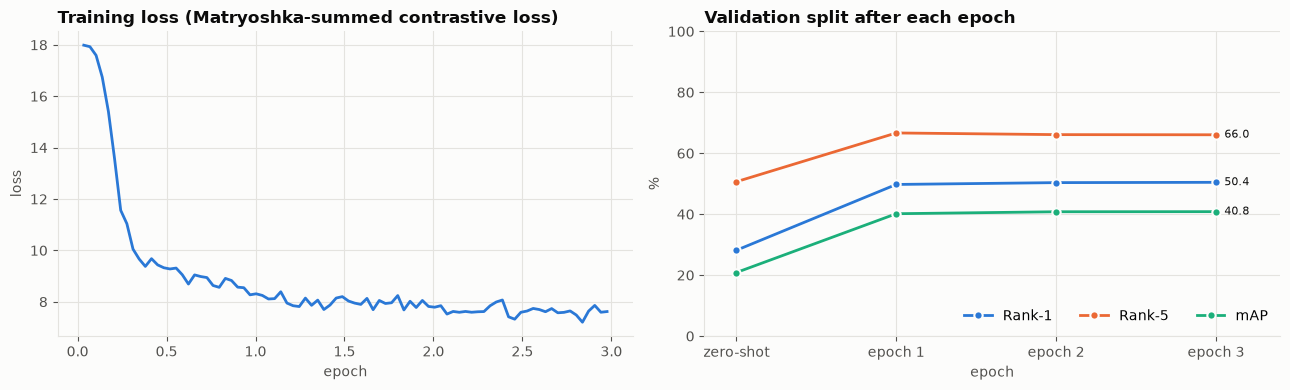

,epoch,eval_val_cosine_accuracy@1,eval_val_cosine_accuracy@5,eval_val_cosine_map@1000
0,0.0,0.2815,0.5065,0.2085
1,1.0,0.4975,0.6665,0.4015
2,2.0,0.5035,0.6610,0.4079
3,3.0,0.5045,0.6605,0.4082


In [6]:
history = pd.DataFrame(trainer.state.log_history)
train_log = history.dropna(subset=["loss"])[["step", "epoch", "loss"]]
val_log = history.dropna(subset=[METRIC])[["epoch", "eval_val_cosine_accuracy@1", "eval_val_cosine_accuracy@5", METRIC]]
val_log = pd.concat([
    pd.DataFrame([{"epoch": 0.0, "eval_val_cosine_accuracy@1": zero_val["val_cosine_accuracy@1"],
                   "eval_val_cosine_accuracy@5": zero_val["val_cosine_accuracy@5"], METRIC: zero_val["val_cosine_map@1000"]}]),
    val_log,
], ignore_index=True)
val_log.to_csv(OUT_DIR / "val_history.csv", index=False)

evals: list[int] = list(range(len(val_log)))   # 0 = zero-shot, then one evaluation per epoch
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
ax1.plot(train_log.epoch, train_log.loss, color=SERIES[0])
ax1.set_title("Training loss (Matryoshka-summed contrastive loss)")
ax1.set_xlabel("epoch"); ax1.set_ylabel("loss")
for i, (col, label) in enumerate([("eval_val_cosine_accuracy@1", "Rank-1"), ("eval_val_cosine_accuracy@5", "Rank-5"), (METRIC, "mAP")]):
    ax2.plot(evals, 100 * val_log[col], color=SERIES[i], marker="o", markersize=6,
             markeredgecolor=SURFACE, markeredgewidth=1.5, label=label)
    ax2.annotate(f"{100 * val_log[col].iloc[-1]:.1f}", (evals[-1], 100 * val_log[col].iloc[-1]),
                 xytext=(6, 0), textcoords="offset points", va="center", fontsize=8, color=INK)
ax2.set_xticks(evals, ["zero-shot"] + [f"epoch {e}" for e in evals[1:]])
ax2.set_ylim(0, 100); ax2.set_xlim(-0.2, len(evals) - 0.6)
ax2.set_title("Validation split after each epoch"); ax2.set_xlabel("epoch"); ax2.set_ylabel("%")
ax2.legend(loc="lower right", ncols=3)
plt.tight_layout()
fig.savefig(OUT_DIR / "training_curves.png", dpi=150)
plt.show()
val_log.round(4)

## 5 · Test results

In [7]:
tuned: dict[str, Retrieval] = {name: evaluate_splits(model, s, FULL_DIM) for name, s in GALLERIES.items()}
zero_280 = pd.read_csv("outputs/results_main.csv").iloc[0]   # TBPR_ex.ipynb, Protocol A, default 280 tokens

METRICS: list[str] = ["Rank-1", "Rank-5", "Rank-10", "mAP", "mINP"]
rows = [{"model": "zero-shot · 280 tokens", "gallery": "test", **{m: float(zero_280[m]) for m in METRICS}}]
for g in GALLERIES:
    rows.append({"model": "zero-shot · 70 tokens", "gallery": g, **summarize(zero_shot[g])})
    rows.append({"model": "fine-tuned · 70 tokens", "gallery": g, **summarize(tuned[g])})
results = pd.DataFrame(rows)
results.to_csv(OUT_DIR / "results_test.csv", index=False)
results.round(2)

,model,gallery,Rank-1,Rank-5,Rank-10,mAP,mINP
0,zero-shot · 280 tokens,test,35.45,59.50,70.00,25.00,7.59
1,zero-shot · 70 tokens,test,40.05,65.45,75.40,28.76,9.65
2,fine-tuned · 70 tokens,test,71.40,87.25,93.15,54.76,29.45
3,zero-shot · 70 tokens,val+test,26.67,48.32,58.58,18.58,4.98
4,fine-tuned · 70 tokens,val+test,55.92,72.42,78.75,42.50,20.83


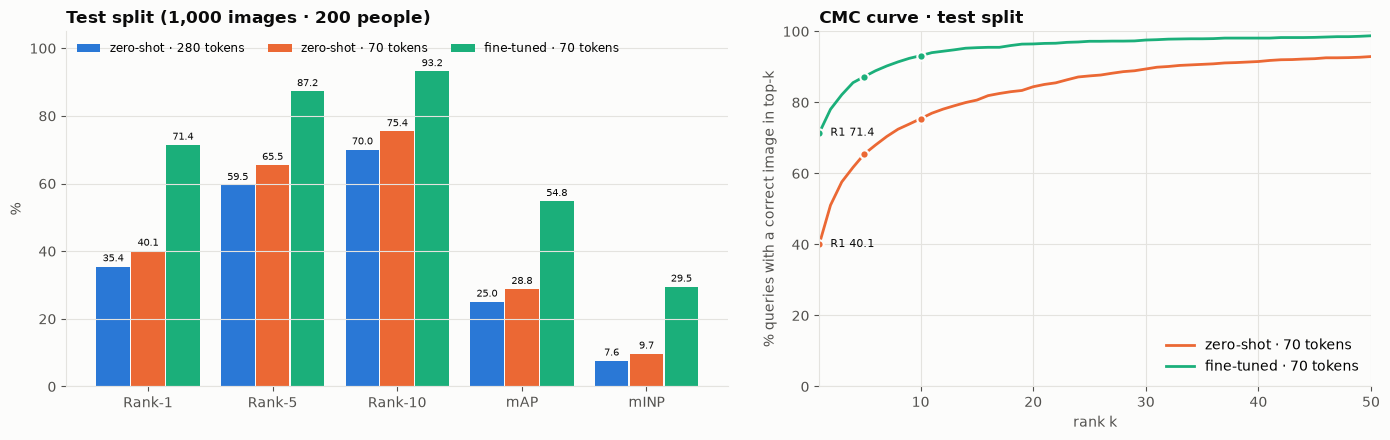

In [8]:
test_rows = results[results.gallery == "test"].reset_index(drop=True)
x = np.arange(len(METRICS))
w = 0.27
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1.2, 1]})
for i, row in test_rows.iterrows():
    bars = ax1.bar(x + (i - 1) * (w + 0.01), [row[m] for m in METRICS], w, color=SERIES[i], label=row["model"])
    ax1.bar_label(bars, fmt="%.1f", padding=2, fontsize=7.5, color=INK)
ax1.set_xticks(x, METRICS); ax1.set_ylim(0, 105); ax1.set_ylabel("%")
ax1.grid(axis="x", visible=False)
ax1.set_title("Test split (1,000 images · 200 people)")
ax1.legend(loc="upper left", ncols=3, fontsize=8.5)

K: int = 50
for i, (name, r) in enumerate([("zero-shot · 70 tokens", zero_shot["test"]), ("fine-tuned · 70 tokens", tuned["test"])]):
    curve = cmc(r, K)
    ax2.plot(range(1, K + 1), curve, color=SERIES[i + 1], label=name)
    for k in (1, 5, 10):
        ax2.plot(k, curve[k - 1], "o", color=SERIES[i + 1], markersize=6, markeredgecolor=SURFACE, markeredgewidth=1.5)
    ax2.annotate(f"R1 {curve[0]:.1f}", (1, curve[0]), xytext=(8, -2), textcoords="offset points", fontsize=8, color=INK)
ax2.set_xlim(1, K); ax2.set_ylim(0, 100)
ax2.set_xlabel("rank k"); ax2.set_ylabel("% queries with a correct image in top-k")
ax2.set_title("CMC curve · test split")
ax2.legend(loc="lower right")
plt.tight_layout()
fig.savefig(OUT_DIR / "results_test.png", dpi=150)
plt.show()

### Matryoshka dimensions after fine-tuning (test split)

In [9]:
q_idx = np.flatnonzero(captions.split == "test")
g_idx = np.flatnonzero(img_split == "test")
q_emb, g_emb = encode_queries(model, q_idx), encode_images(model, g_idx)
dims = pd.DataFrame([
    {"dim": d, **summarize(retrieve(q_emb, captions.pids[q_idx], g_emb, img_pids[g_idx], d, EVAL_CHUNK))}
    for d in MATRYOSHKA_DIMS
])
dims.to_csv(OUT_DIR / "results_dims.csv", index=False)
dims.round(2)

,dim,Rank-1,Rank-5,Rank-10,mAP,mINP
0,768,71.40,87.25,93.15,54.76,29.45
1,512,71.05,87.55,92.70,54.49,29.50
2,256,70.10,86.40,92.90,53.54,28.71
3,128,65.05,84.50,91.10,50.43,25.76


## 6 · Before / after examples (test split)
Queries the zero-shot model missed at rank 1 that the fine-tuned model gets right. Aqua frame = correct person, orange = wrong.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


fixed by fine-tuning: 678 queries | broken by fine-tuning: 51


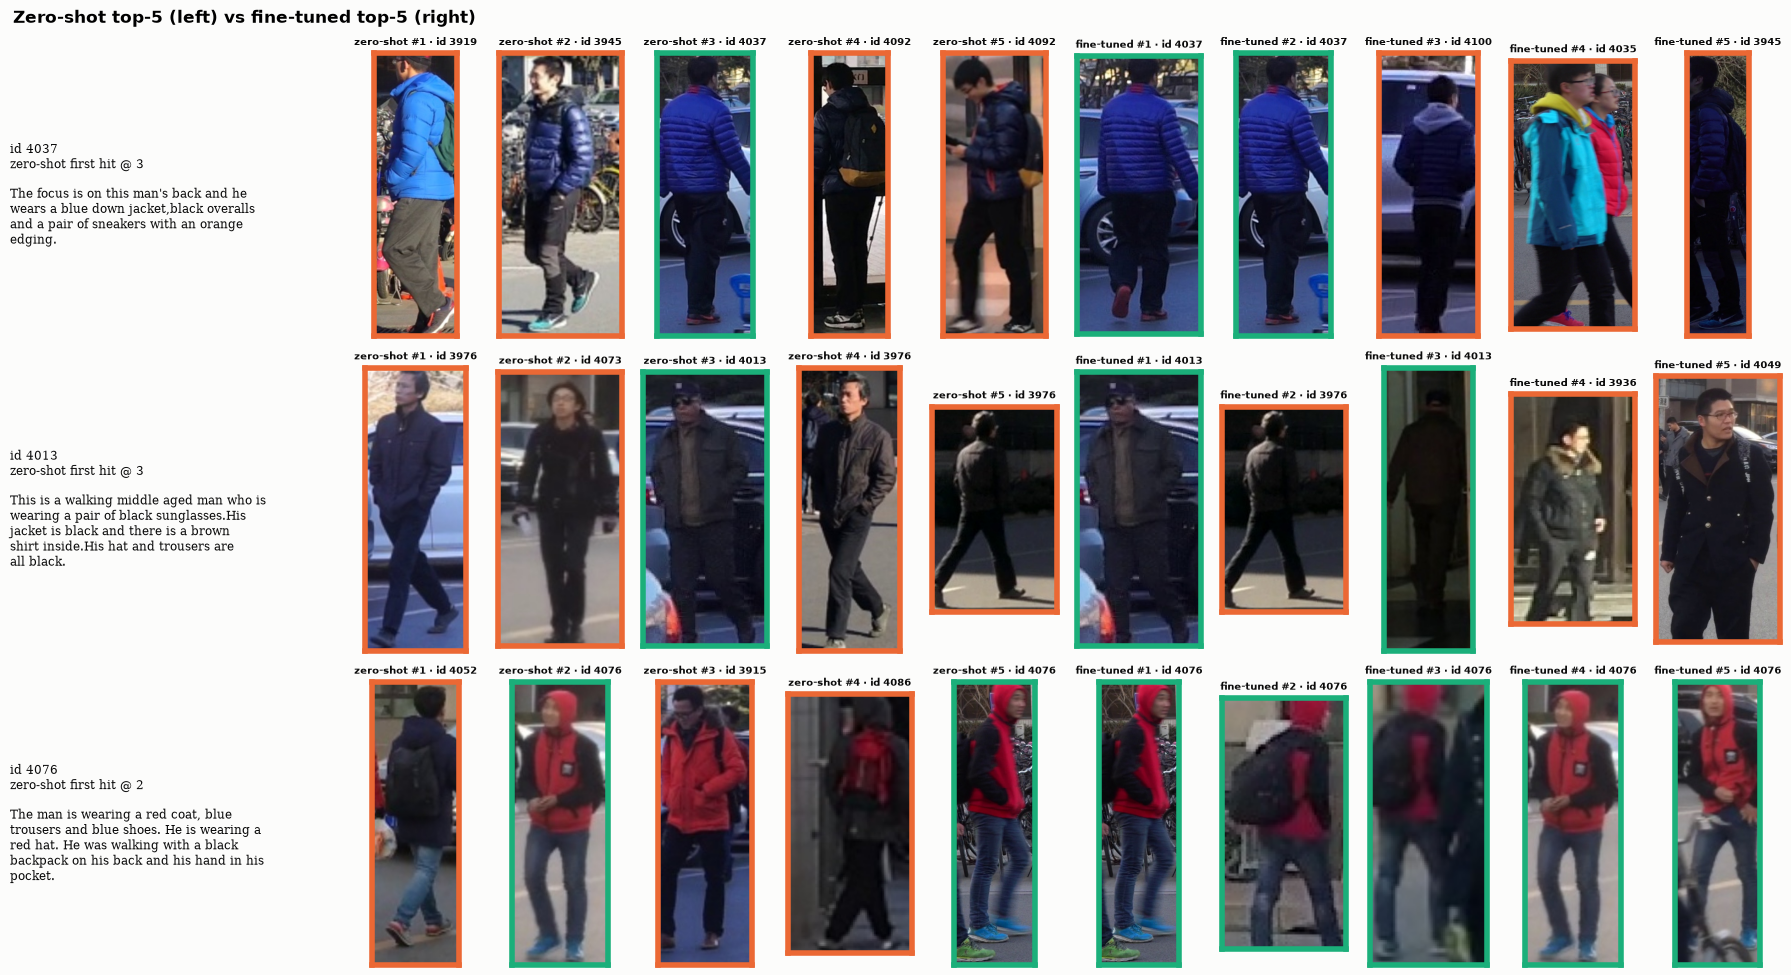

In [10]:
def wrap(text: str, width: int) -> str:
    out, line = [], ""
    for word in text.split():
        if len(line) + len(word) + 1 > width:
            out.append(line)
            line = word
        else:
            line = f"{line} {word}".strip()
    return "\n".join(out + [line])


def draw_top5(axes: Sequence[plt.Axes], top5: np.ndarray, g_idx: np.ndarray, pid: int, label: str) -> None:
    for k, (ax, gi) in enumerate(zip(axes, top5)):
        rec = records[int(g_idx[gi])]
        ok = rec.pid == pid
        ax.imshow(Image.open(IMG_DIR / rec.img_path))
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        for s in ax.spines.values():
            s.set_visible(True); s.set_edgecolor(SERIES[2] if ok else SERIES[1]); s.set_linewidth(4)
        ax.set_title(f"{label} #{k + 1} · id {rec.pid}", fontsize=7.5, loc="center")


fixed = np.flatnonzero((zero_shot["test"].first_hit > 1) & (tuned["test"].first_hit == 1))
print(f"fixed by fine-tuning: {len(fixed)} queries | broken by fine-tuning: "
      f"{int(((zero_shot['test'].first_hit == 1) & (tuned['test'].first_hit > 1)).sum())}")
pick = np.random.default_rng(SEED).choice(fixed, 3, replace=False)
fig, axes = plt.subplots(len(pick), 11, figsize=(18, 3.3 * len(pick)), gridspec_kw={"width_ratios": [2.6] + [1] * 10})
for line, qi in zip(axes, pick):
    cap_i = int(q_idx[qi])
    pid = int(captions.pids[cap_i])
    line[0].axis("off")
    line[0].text(0, 0.5, f"id {pid}\nzero-shot first hit @ {zero_shot['test'].first_hit[qi]}\n\n" + wrap(captions.texts[cap_i], 40),
                 va="center", fontsize=8.5, color=INK, family="serif")
    draw_top5(line[1:6], zero_shot["test"].top5[qi], g_idx, pid, "zero-shot")
    draw_top5(line[6:], tuned["test"].top5[qi], g_idx, pid, "fine-tuned")
fig.suptitle("Zero-shot top-5 (left) vs fine-tuned top-5 (right)", x=0.01, ha="left", fontweight="semibold")
plt.tight_layout()
fig.savefig(OUT_DIR / "examples_before_after.png", dpi=120)
plt.show()

## 7 · Embeddings for the web demo
All 20,505 images are encoded with the fine-tuned model (the demo's *entire dataset* gallery includes training images — fine for browsing, not for scoring).

In [11]:
all_emb = encode_images(model, np.arange(len(records))).cpu().numpy().astype(np.float32)
np.save(OUT_DIR / "image_embeddings.npy", all_emb)
print(all_emb.shape, "->", (OUT_DIR / "image_embeddings.npy").resolve())

(20505, 768) -> /home/super/Desktop/Advanced AI Models/Gemma_ebmedding_2/outputs/finetuned/image_embeddings.npy


## 8 · Summary

In [12]:
print(results.round(1).to_string(index=False))
print("\nmodel:", MODEL_DIR.resolve())
for f in sorted(OUT_DIR.iterdir()):
    print("  ", f.name)

                 model  gallery  Rank-1  Rank-5  Rank-10  mAP  mINP
zero-shot · 280 tokens     test    35.4    59.5     70.0 25.0   7.6
 zero-shot · 70 tokens     test    40.1    65.4     75.4 28.8   9.7
fine-tuned · 70 tokens     test    71.4    87.2     93.2 54.8  29.5
 zero-shot · 70 tokens val+test    26.7    48.3     58.6 18.6   5.0
fine-tuned · 70 tokens val+test    55.9    72.4     78.8 42.5  20.8

model: /home/super/Desktop/Advanced AI Models/Gemma_ebmedding_2/models/embeddinggemma2-rstpreid
   examples_before_after.png
   image_embeddings.npy
   results_dims.csv
   results_test.csv
   results_test.png
   training_curves.png
   val_history.csv


### Findings

| Model | Gallery | Rank-1 | Rank-5 | Rank-10 | mAP | mINP |
|---|---|---|---|---|---|---|
| zero-shot · 280 tokens | test | 35.5 | 59.5 | 70.0 | 25.0 | 7.6 |
| zero-shot · 70 tokens | test | 40.1 | 65.5 | 75.4 | 28.8 | 9.7 |
| **fine-tuned · 70 tokens** | test | **71.4** | **87.3** | **93.2** | **54.8** | **29.5** |
| zero-shot · 70 tokens | val + test (400 people) | 26.7 | 48.3 | 58.6 | 18.6 | 5.0 |
| **fine-tuned · 70 tokens** | val + test (400 people) | **55.9** | **72.4** | **78.8** | **42.5** | **20.8** |

* **Fine-tuning gains +31 Rank-1 and +26 mAP on the unseen test split.** 678 test queries move to rank 1, and 51 drop out of rank 1.
* **No leakage.** Train, val and test share no people, no images and no identical description text. The checkpoint was selected on val only.
* **Training converges in one epoch.** Val Rank-1 is 49.8 → 50.4 → 50.5 over epochs 1–3. Training took 88 min on an RTX 3090 (289 steps per epoch).
* **Val is a harder split than test.** Zero-shot Rank-1 is 28 on val vs 40 on test, so the absolute val and test numbers are not directly comparable.
* For reference, published RSTPReid results are ≈50 Rank-1 for a fine-tuned CLIP ViT-B/32 and ≈60–68 for specialised methods (IRRA 60.2, RDE 65.4, MARS 67.6). Those use different backbones and protocols, so treat this as a rough comparison, not a leaderboard claim.
* Matryoshka still works after fine-tuning: 512 dims costs −0.4 Rank-1, 256 dims −1.3, 128 dims −6.4.